# Introducción a la optimización combinatoria y las metaheurísticas

**Serie:** Metaheurísticas desde cero · Notebook 01 · Siguiente: [02 · Métodos constructivos](../01-metodos-de-trayectoria/02-metodos-constructivos.ipynb)

## Tabla de contenido
1. Qué es optimizar: formulación general
2. Tres problemas combinatorios de referencia: TSP, mochila y QAP
3. La explosión combinatoria
4. Exacto vs. heurística vs. metaheurística
5. Paisajes de aptitud, vecindarios y óptimos locales
6. Intensificación vs. diversificación
7. Taxonomía de las metaheurísticas
8. El teorema *No Free Lunch*
9. La búsqueda aleatoria como línea base
10. Cómo medir: gap, cotas y mejor valor conocido
11. Crítica a la metáfora
12. Resumen, ejercicios y referencias

## Qué vas a aprender / Prerrequisitos

**Vas a aprender a**
- formular un problema de optimización combinatoria (espacio de búsqueda, función objetivo, factibilidad);
- medir *qué tan grande* es un espacio de búsqueda y por qué la fuerza bruta deja de ser opción;
- entender qué es un **vecindario**, un **óptimo local** y una **cuenca de atracción**, calculándolos de forma exhaustiva en una instancia pequeña;
- distinguir métodos exactos, heurísticas y metaheurísticas, y los dos ejes que gobiernan toda metaheurística (intensificación y diversificación);
- ubicar cualquier algoritmo en una taxonomía (trayectoria/poblacional, con/sin memoria);
- explicar qué dice (y qué *no* dice) el teorema No Free Lunch, verificándolo por enumeración;
- usar la **búsqueda aleatoria** como línea base honesta y reportar resultados con **gap**.

**Prerrequisitos:** Python y NumPy básicos, nociones de complejidad algorítmica ($O(\cdot)$) y de probabilidad elemental. No se necesita nada de optimización previa.

> Todo el código es autocontenido (NumPy + Matplotlib), con semillas fijas.

In [1]:
import itertools, math, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)      # generador reproducible para toda la notebook

## 1. Qué es optimizar

Un problema de optimización queda definido por una terna $(X, \mathcal{F}, f)$:

- $X$: **espacio de búsqueda** (todas las configuraciones que podemos describir);
- $\mathcal{F}\subseteq X$: **región factible** (las que cumplen las restricciones);
- $f:\mathcal{F}\to\mathbb{R}$: **función objetivo** (por convención, minimizar).

$$
x^\star \in \arg\min_{x\in\mathcal{F}} f(x), \qquad f^\star = f(x^\star).
$$

La optimización es **combinatoria** cuando $X$ es discreto y finito (permutaciones, subconjuntos, asignaciones, particiones...). Aquí no hay gradientes ni continuidad que explotar: la estructura está en *cómo se combinan los componentes*.

Dos nociones que usaremos en todas estas notebooks:

- **Óptimo global:** $x^\star$ tal que $f(x^\star)\le f(x)$ para todo $x\in\mathcal{F}$.
- **Óptimo local respecto a un vecindario $N$:** $\hat{x}$ tal que $f(\hat{x})\le f(y)$ para todo $y\in N(\hat{x})$. Depende **del vecindario elegido**, no solo de $f$ (lo veremos con un ejemplo).

Que el espacio sea finito *no* hace el problema fácil: enumerar es, en principio, posible pero casi siempre inviable. Muchos problemas combinatorios clásicos son **NP-difíciles** (Garey & Johnson, 1979): no se conoce un algoritmo exacto de tiempo polinomial y se cree que no existe. Las metaheurísticas nacen para obtener **buenas soluciones en tiempo razonable** sin garantía de optimalidad.

## 2. Tres problemas combinatorios de referencia

### 2.1 Problema del agente viajero (TSP)

Dadas $n$ ciudades y distancias $d_{ij}$, encontrar el ciclo hamiltoniano de menor longitud. Con una permutación $\pi$ de las ciudades:

$$
f(\pi)=\sum_{k=1}^{n} d_{\pi(k),\,\pi((k\bmod n)+1)}.
$$

El espacio de búsqueda son las $n!$ permutaciones, pero como rotar el punto de partida o recorrer el ciclo al revés no cambia la longitud, hay $\frac{(n-1)!}{2}$ tours **distintos** (caso simétrico).

### 2.2 Problema de la mochila 0/1

$n$ ítems con valor $v_i$ y peso $w_i$; elegir $x\in\{0,1\}^n$ que maximice $\sum v_ix_i$ sujeto a $\sum w_ix_i\le W$. Espacio: $2^n$ vectores binarios, parte de ellos infactibles. Es una buena ilustración de **restricciones** y de representación binaria.

### 2.3 Problema de asignación cuadrática (QAP)

Asignar $n$ instalaciones a $n$ ubicaciones; $F_{ij}$ es el flujo entre instalaciones y $D_{kl}$ la distancia entre ubicaciones. Con $p(i)$ = ubicación de la instalación $i$:

$$
f(p)=\sum_{i=1}^{n}\sum_{j=1}^{n} F_{ij}\,D_{p(i),p(j)}.
$$

Espacio: $n!$ permutaciones. Es notoriamente difícil: instancias de tamaño modesto ($n\approx 30$) ya son un reto para los métodos exactos (Koopmans & Beckmann, 1957 introducen el problema).

Implementamos las utilidades mínimas de cada uno, con una función `es_permutacion` para **validar** soluciones.

In [2]:
# ---------- TSP ----------
def crear_tsp(n, rng):
    # Instancia euclídea aleatoria en el cuadrado unitario: coordenadas y matriz de distancias.
    pts = rng.random((n, 2))
    return pts, cdist(pts, pts)

def longitud_tour(D, tour):
    # Longitud del ciclo: suma de D[t_k, t_{k+1}] incluyendo el cierre.
    tour = np.asarray(tour)
    return D[tour, np.roll(tour, -1)].sum()

def es_permutacion(sol, n):
    # Valida que sol sea una permutación de {0,...,n-1}.
    sol = np.asarray(sol)
    return sol.shape == (n,) and np.array_equal(np.sort(sol), np.arange(n))

def graficar_tour(pts, tour, ax=None, titulo=""):
    ax = ax or plt.gca()
    t = np.append(tour, tour[0])
    ax.plot(pts[t, 0], pts[t, 1], "-o", ms=4, lw=1.2)
    ax.set_title(titulo); ax.set_aspect("equal"); ax.grid(False)

# ---------- Mochila ----------
def crear_mochila(n, rng):
    w = rng.integers(5, 40, n); v = (w * rng.uniform(0.8, 1.6, n)).round().astype(int) + rng.integers(0, 6, n)
    return v, w, int(0.4 * w.sum())

def valor_mochila(x, v, w, W):
    # Devuelve (valor, factible).
    x = np.asarray(x)
    return (int(x @ v), bool(x @ w <= W))

# ---------- QAP ----------
def crear_qap(n, rng):
    F = rng.integers(0, 10, (n, n)); F = np.triu(F, 1); F = F + F.T
    pts = rng.random((n, 2)); D = cdist(pts, pts)
    return F.astype(float), D

def costo_qap(F, D, p):
    # f(p) = sum_ij F_ij * D_{p(i) p(j)}
    p = np.asarray(p)
    return (F * D[np.ix_(p, p)]).sum()

pts, D = crear_tsp(12, rng)
t = rng.permutation(12)
print("tour aleatorio válido:", es_permutacion(t, 12), "| longitud:", round(longitud_tour(D, t), 3))

tour aleatorio válido: True | longitud: 6.379


## 3. La explosión combinatoria

Si evaluar un tour cuesta $1\,\mu s$ (optimista en Python, razonable en C), enumerar todos los tours de $n$ ciudades toma $\frac{(n-1)!}{2}\,\mu s$. Calculamos el tamaño del espacio con `lgamma` (para no desbordar) y el tiempo de enumeración a $10^9$ evaluaciones por segundo, un supuesto *generoso*: una evaluación por nanosegundo.

   n    tours distintos     años @1e9 eval/s
   5          1.200e+01            3.802e-16
  10          1.814e+05            5.749e-12
  15          4.359e+10            1.381e-06
  20          6.082e+16            1.927e+00
  25          3.102e+23            9.830e+06
  30          4.421e+30            1.401e+14
  50          3.041e+62            9.637e+45
 100         4.666e+155           1.479e+139


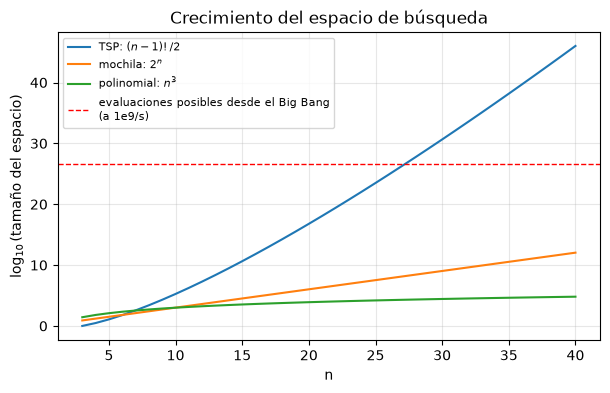

In [3]:
def log10_tours(n):
    # log10((n-1)!/2) usando lgamma(n) = ln((n-1)!)
    return (math.lgamma(n) - math.log(2)) / math.log(10)

SEG_ANIO = 3.156e7
print(f"{'n':>4} {'tours distintos':>18} {'años @1e9 eval/s':>20}")
for n in [5, 10, 15, 20, 25, 30, 50, 100]:
    l = log10_tours(n)
    anios = 10 ** (l - 9) / SEG_ANIO if l - 9 < 300 else float("inf")
    tours = f"{10**l:.3e}" if l < 300 else f"10^{l:.0f}"
    print(f"{n:>4} {tours:>18} {anios:>20.3e}")

ns = np.arange(3, 41)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ns, [log10_tours(n) for n in ns], label=r"TSP: $(n-1)!/2$")
ax.plot(ns, ns * np.log10(2), label=r"mochila: $2^n$")
ax.plot(ns, 3 * np.log10(ns), label=r"polinomial: $n^3$")
ax.axhline(np.log10(1e9 * SEG_ANIO * 13.8e9), color="r", ls="--", lw=1, label="evaluaciones posibles desde el Big Bang\n(a 1e9/s)")
ax.set_xlabel("n"); ax.set_ylabel(r"$\log_{10}$(tamaño del espacio)")
ax.set_title("Crecimiento del espacio de búsqueda"); ax.legend(fontsize=8); plt.show()

Con $n\approx 20$ ciudades la enumeración a $10^9$ evaluaciones/s tarda años; con $n=30$ supera la edad del universo por muchos órdenes de magnitud. Y $n=30$ es una instancia diminuta. El mensaje: **no se trata de computadoras más rápidas**, sino de no enumerar.

### Existen exactos más inteligentes que la fuerza bruta, pero también explotan
El algoritmo de **Held–Karp** (programación dinámica sobre subconjuntos; Held & Karp, 1962; Bellman, 1962) resuelve el TSP en $O(n^2 2^n)$. Es *mucho* mejor que $O(n!)$, pero sigue siendo exponencial. Lo implementamos para (i) tener **óptimos exactos** de instancias pequeñas con los que medir gaps y (ii) comparar tiempos con la fuerza bruta.

In [4]:
def tsp_fuerza_bruta(D):
    # Enumera (n-1)! permutaciones fijando la ciudad 0 (no divide por 2: simple y verificable).
    n = len(D)
    perms = np.array(list(itertools.permutations(range(1, n))), dtype=np.int16)
    ruta = np.concatenate([np.zeros((len(perms), 1), np.int16), perms], axis=1)
    L = D[ruta, np.roll(ruta, -1, axis=1)].sum(axis=1)
    k = L.argmin()
    return L[k], ruta[k]

def tsp_held_karp(D):
    # Programación dinámica: dp[S, j] = costo mínimo de partir en 0, visitar el conjunto S
    # (bitmask sobre las ciudades 1..n-1) y terminar en j.
    n = len(D); m = n - 1
    dp = np.full((1 << m, m), np.inf); padre = np.full((1 << m, m), -1, dtype=np.int16)
    for j in range(m):
        dp[1 << j, j] = D[0, j + 1]
    for S in range(1, 1 << m):
        for j in range(m):
            if not (S >> j) & 1 or S == (1 << j):
                continue
            prev = S ^ (1 << j)
            cand = dp[prev] + D[1:, j + 1]     # terminar en k (k in prev) y saltar k -> j
            k = int(cand.argmin()); dp[S, j] = cand[k]; padre[S, j] = k
    full = (1 << m) - 1
    cierre = dp[full] + D[1:, 0]
    j = int(cierre.argmin()); costo = cierre[j]
    tour = [0]; S = full                        # reconstrucción del tour
    while j != -1:
        tour.append(j + 1); pj = int(padre[S, j]); S ^= (1 << j); j = pj
    return costo, np.array(tour)

# Verificación: ambos exactos deben coincidir
pts9, D9 = crear_tsp(9, rng)
t0 = time.perf_counter(); c_bf, r_bf = tsp_fuerza_bruta(D9); t_bf = time.perf_counter() - t0
t0 = time.perf_counter(); c_hk, r_hk = tsp_held_karp(D9); t_hk = time.perf_counter() - t0
assert abs(c_bf - c_hk) < 1e-9 and es_permutacion(r_hk, 9) and abs(longitud_tour(D9, r_hk) - c_hk) < 1e-9
print(f"n=9: fuerza bruta={c_bf:.4f} ({t_bf:.2f}s)  Held-Karp={c_hk:.4f} ({t_hk:.2f}s)  -> coinciden")

print("\nTiempos (s)    n   fuerza bruta   Held-Karp")
for n in [8, 9, 10, 11, 12, 13, 14]:
    _, Dn = crear_tsp(n, np.random.default_rng(n))
    a = "-"
    if n <= 10:
        t0 = time.perf_counter(); tsp_fuerza_bruta(Dn); a = f"{time.perf_counter()-t0:8.3f}"
    t0 = time.perf_counter(); tsp_held_karp(Dn); b = time.perf_counter() - t0
    print(f"{n:>17} {a:>12} {b:10.3f}")

n=9: fuerza bruta=2.6057 (0.02s)  Held-Karp=2.6057 (0.00s)  -> coinciden

Tiempos (s)    n   fuerza bruta   Held-Karp
                8        0.004      0.001
                9        0.018      0.001


               10        0.198      0.003
               11            -      0.006
               12            -      0.013
               13            -      0.028
               14            -      0.063


La fuerza bruta se multiplica por $\approx n$ al subir una ciudad ($n!$); Held–Karp por $\approx 2$ ($2^n$) más un factor polinomial. Ambos son exponenciales. Usaremos Held–Karp para obtener el **óptimo exacto** de instancias de hasta ~14 ciudades; más allá, hace falta otra cosa.

### Los otros dos problemas: espacio y factibilidad
Para la mochila y el QAP conviene ver la *estructura del vecindario natural*:
- **Mochila:** vecino = cambiar el estado de un bit ("flip") $\Rightarrow |N(x)|=n$. Las restricciones introducen soluciones infactibles: hay que decidir si se **reparan**, se **penalizan** o se **prohíben** (decisión de diseño que reaparece en todas estas notebooks).
- **QAP/TSP por permutación:** vecino = intercambiar dos posiciones ("swap") $\Rightarrow |N(p)|=\binom{n}{2}$.

In [5]:
# Mochila: espacio 2^n, exacto por DP y fuerza bruta; comparación con voraz por razón valor/peso
v, w, W = crear_mochila(16, rng)
n = len(v)
X = ((np.arange(2**n)[:, None] >> np.arange(n)) & 1).astype(np.int32)   # los 2^n vectores binarios
peso, valor = X @ w, X @ v
fact = peso <= W
print(f"n={n}: {2**n} soluciones, factibles: {fact.sum()} ({100*fact.mean():.1f}%)")
opt_bf = valor[fact].max()

# DP exacta O(nW)
dp = np.zeros(W + 1, dtype=int)
for i in range(n):
    dp[w[i]:] = np.maximum(dp[w[i]:], dp[:W + 1 - w[i]] + v[i])
assert dp[W] == opt_bf
# Voraz por razón v/w
orden = np.argsort(-v / w); xg = np.zeros(n, int); cap = W
for i in orden:
    if w[i] <= cap: xg[i] = 1; cap -= w[i]
print("óptimo (fuerza bruta = DP):", opt_bf, "| voraz v/w:", valor_mochila(xg, v, w, W)[0])

n=16: 65536 soluciones, factibles: 15119 (23.1%)
óptimo (fuerza bruta = DP): 219 | voraz v/w: 215


In [6]:
# QAP: espacio n!, cardinalidad del vecindario swap y óptimo exacto por enumeración en n=8
F8, D8 = crear_qap(8, rng)
perms = np.array(list(itertools.permutations(range(8))), dtype=np.int8)
t0 = time.perf_counter()
costos = np.array([costo_qap(F8, D8, p) for p in perms])
print(f"QAP n=8: {len(perms)} permutaciones evaluadas en {time.perf_counter()-t0:.1f}s")
print(f"óptimo={costos.min():.3f}  media={costos.mean():.3f}  peor={costos.max():.3f}")
print("tamaño del vecindario swap para n=8:", math.comb(8, 2), "| para n=30:", math.comb(30, 2))

QAP n=8: 40320 permutaciones evaluadas en 0.2s
óptimo=85.472  media=107.352  peor=124.944
tamaño del vecindario swap para n=8: 28 | para n=30: 435


## 4. Exacto vs. heurística vs. metaheurística

| | **Método exacto** | **Heurística** | **Metaheurística** |
|---|---|---|---|
| Garantía | Óptimo global (y prueba) | Ninguna (a veces una razón de aproximación) | Ninguna |
| Diseño | Específico del problema (B&B, DP, ILP) | Específica del problema (constructivo, mejora) | **Marco general** que se *instancia* al problema |
| Tiempo | Exponencial en el peor caso | Rápida | Controlable por presupuesto |
| Ejemplo | Held–Karp, Branch & Cut | Vecino más cercano, 2-opt | Recocido simulado, tabú, GA, ACO |
| Cuándo | $n$ pequeño o estructura favorable | Solución rápida / punto de partida | Instancias grandes, restricciones raras, poco tiempo |

Una **metaheurística** es un marco algorítmico de alto nivel, independiente del problema, que coordina heurísticas subordinadas (construcción, mejora local, perturbación) para explorar el espacio de forma eficaz (Blum & Roli, 2003; Gendreau & Potvin, 2010). Dos matices importantes:

1. "Meta" no significa "mejor": una heurística *específica* bien hecha suele superar a una metaheurística genérica sin adaptar. La ganancia de las metaheurísticas es **robustez y flexibilidad** (cambiar el problema = cambiar solo la codificación, el vecindario y la evaluación).
2. Los métodos exactos y los metaheurísticos son **complementarios**: las cotas inferiores (p. ej. relajaciones) dan una vara para medir la calidad de una metaheurística (sección 10).

## 5. Paisajes de aptitud, vecindarios y óptimos locales

Un **paisaje de aptitud** (*fitness landscape*; idea que se remonta a Wright, 1932, en genética) es la terna $(X, N, f)$: el espacio, una relación de vecindad $N$ y la función objetivo. Imagina $X$ como el terreno, $N$ como "caminar un paso" y $f$ como la altitud. Una búsqueda local es una caminata cuesta abajo en ese terreno; un **óptimo local** es un valle donde todos los pasos suben.

### 5.1 El óptimo local depende del vecindario
Tomemos una función sobre enteros $x\in\{0,\dots,255\}$ (8 bits) y contemos los mínimos locales bajo dos vecindarios: $\pm 1$ en el entero, o voltear un bit. La **función es la misma**; cambian los óptimos locales.

mínimos locales con vecindario ±1: 82 | con flip de bit: 10 | mínimo global en x = 85


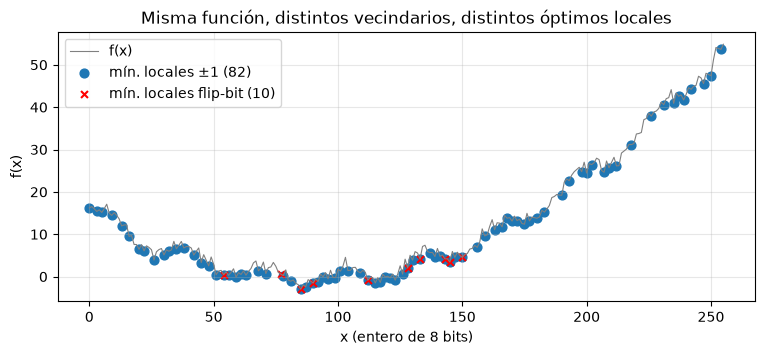

In [7]:
r2 = np.random.default_rng(7)
xs = np.arange(256)
# función rugosa: tendencia suave + ruido fijo -> muchos valles
fx = 0.002 * (xs - 90.0) ** 2 + r2.normal(0, 1.0, 256) + 2 * np.sin(xs / 5.0)

def minimos_locales(f, vecinos):
    return [x for x in range(len(f)) if all(f[x] <= f[y] for y in vecinos(x))]

vec_pm1 = lambda x: [y for y in (x - 1, x + 1) if 0 <= y < 256]
vec_bit = lambda x: [x ^ (1 << b) for b in range(8)]
ml1, ml2 = minimos_locales(fx, vec_pm1), minimos_locales(fx, vec_bit)
print("mínimos locales con vecindario ±1:", len(ml1), "| con flip de bit:", len(ml2), "| mínimo global en x =", fx.argmin())

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(xs, fx, lw=0.8, color="gray", label="f(x)")
ax.scatter(ml1, fx[ml1], s=40, label=f"mín. locales ±1 ({len(ml1)})")
ax.scatter(ml2, fx[ml2], s=25, marker="x", color="r", label=f"mín. locales flip-bit ({len(ml2)})")
ax.set_xlabel("x (entero de 8 bits)"); ax.set_ylabel("f(x)"); ax.set_title("Misma función, distintos vecindarios, distintos óptimos locales")
ax.legend(); plt.show()

La lección de diseño: **elegir el vecindario es elegir el paisaje**. Un buen vecindario produce un paisaje "suave" (soluciones vecinas tienen aptitud parecida y pocos óptimos locales); uno malo, un paisaje rugoso.

### 5.2 Un paisaje TSP completo (enumeración exhaustiva)
Con $n=9$ ciudades hay $\frac{8!}{2}=20\,160$ tours distintos: podemos construir *todo* el paisaje bajo el vecindario **2-opt** (quitar dos aristas y reconectar invirtiendo un tramo; $|N|=\frac{n(n-3)}{2}=27$). Para cada tour calculamos:
- si es óptimo local (ningún vecino mejora);
- adónde llega un **descenso por máxima pendiente** (su cuenca de atracción).

Los tours se identifican por una forma canónica (empezar en 0 y orientar el ciclo) para que rotaciones y reflexiones no cuenten como distintos.

In [8]:
n9 = 9
pts9, D9 = crear_tsp(n9, np.random.default_rng(6))

def canonico(t):
    # Forma canónica: rotar para empezar en 0 y orientar con t[1] < t[-1].
    t = list(t); k = t.index(0); t = t[k:] + t[:k]
    if t[1] > t[-1]: t = [t[0]] + t[:0:-1]
    return tuple(t)

todos = [(0,) + p for p in itertools.permutations(range(1, n9)) if p[0] < p[-1]]
costo = {t: longitud_tour(D9, t) for t in todos}
print("tours distintos:", len(todos), "(esperado", math.factorial(n9 - 1) // 2, ")")

def vecinos_2opt(t):
    n = len(t)
    for i in range(1, n - 1):
        for j in range(i + 1, n):
            if i == 1 and j == n - 1: continue          # invertir todo el cuerpo = mismo ciclo
            yield canonico(t[:i] + t[i:j + 1][::-1] + t[j + 1:])

def vecinos_swap(t):
    # Intercambio de dos ciudades NO adyacentes en el ciclo (las adyacentes equivalen a un 2-opt).
    n = len(t)
    for i in range(n - 1):
        for j in range(i + 2, n):
            if i == 0 and j == n - 1: continue
            u = list(t); u[i], u[j] = u[j], u[i]
            yield canonico(u)

print("|N_2opt| =", sum(1 for _ in vecinos_2opt(todos[0])), "| |N_swap| =", sum(1 for _ in vecinos_swap(todos[0])),
      "| fórmula n(n-3)/2 =", n9 * (n9 - 3) // 2)

def analizar(vecinos):
    # Para cada tour: mejor vecino, si es óptimo local, y destino del descenso por máxima pendiente.
    mejor_v, es_loc = {}, {}
    for t in todos:
        vm = min(vecinos(t), key=lambda s: costo[s])
        es_loc[t] = costo[vm] >= costo[t] - 1e-12
        mejor_v[t] = vm
    cuencas = {}
    for t in todos:
        d = t
        while not es_loc[d]:
            d = mejor_v[d]
        cuencas[d] = cuencas.get(d, 0) + 1
    return cuencas

opt_t = min(todos, key=costo.get)
analisis = {"2-opt": analizar(vecinos_2opt), "swap": analizar(vecinos_swap)}
print(f"óptimo global = {costo[opt_t]:.4f}")
for nombre, cu in analisis.items():
    tam = sorted(cu.values(), reverse=True)
    print(f"[{nombre:>5}] óptimos locales: {len(cu):>3} | cuenca del óptimo global: {cu.get(opt_t, 0)} tours "
          f"({100*cu.get(opt_t, 0)/len(todos):.1f}% del espacio) | 3 mayores cuencas: {tam[:3]} | cuencas de 1 solo tour: {tam.count(1)}")

tours distintos: 20160 (esperado 20160 )
|N_2opt| = 27 | |N_swap| = 27 | fórmula n(n-3)/2 = 27


óptimo global = 3.2787
[2-opt] óptimos locales:   3 | cuenca del óptimo global: 17562 tours (87.1% del espacio) | 3 mayores cuencas: [17562, 1530, 1068] | cuencas de 1 solo tour: 0
[ swap] óptimos locales:  41 | cuenca del óptimo global: 964 tours (4.8% del espacio) | 3 mayores cuencas: [1249, 998, 966] | cuencas de 1 solo tour: 0


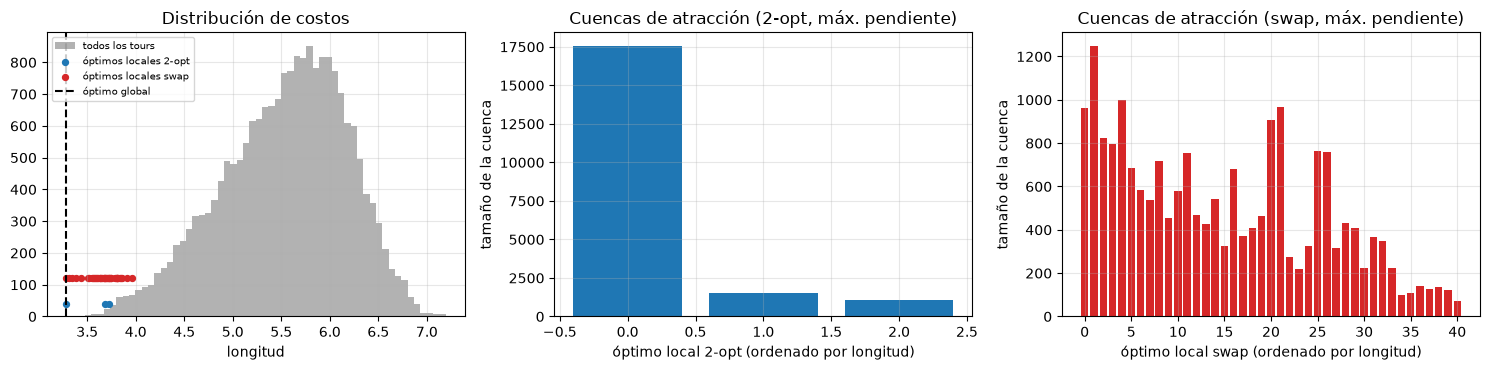

swap: correlación (longitud del óptimo local, tamaño de su cuenca) = -0.798


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
c_all = np.array([costo[t] for t in todos])
axes[0].hist(c_all, bins=60, alpha=0.6, color="gray", label="todos los tours")
for nombre, col in [("2-opt", "C0"), ("swap", "C3")]:
    cl = [costo[t] for t in analisis[nombre]]
    axes[0].scatter(cl, np.full(len(cl), 40) if nombre == "2-opt" else np.full(len(cl), 120), s=18, color=col, label=f"óptimos locales {nombre}")
axes[0].axvline(costo[opt_t], color="k", ls="--", label="óptimo global"); axes[0].set_xlabel("longitud"); axes[0].set_title("Distribución de costos"); axes[0].legend(fontsize=7)
for ax, nombre, col in [(axes[1], "2-opt", "C0"), (axes[2], "swap", "C3")]:
    cu = analisis[nombre]
    orden = sorted(cu, key=costo.get)
    ax.bar(range(len(orden)), [cu[t] for t in orden], color=col)
    ax.set_xlabel(f"óptimo local {nombre} (ordenado por longitud)"); ax.set_ylabel("tamaño de la cuenca"); ax.set_title(f"Cuencas de atracción ({nombre}, máx. pendiente)")
plt.tight_layout(); plt.show()
cu = analisis["swap"]; ol = sorted(cu, key=costo.get)
print("swap: correlación (longitud del óptimo local, tamaño de su cuenca) =", round(np.corrcoef([costo[t] for t in ol], [cu[t] for t in ol])[0, 1], 3))

Observaciones (contrástalas con las cifras impresas arriba):
- **El vecindario cambia radicalmente el paisaje**, aun con el *mismo* tamaño $|N|=27$ y la misma función: con 2-opt hay muy pocos óptimos locales y una cuenca del óptimo global que abarca la mayor parte del espacio; con swap hay muchos más óptimos locales y la cuenca del global es una fracción pequeña. 2-opt "respeta" la geometría del TSP (invertir un tramo cambia solo dos aristas); el swap cambia hasta cuatro aristas y rompe más estructura.
- En el paisaje rugoso (swap) hay una relación negativa clara entre la longitud de un óptimo local y el tamaño de su cuenca: los **mejores valles tienden a ser más anchos**, de modo que un descenso aleatorio suele caer en ellos con más probabilidad (verifica el signo de la correlación impresa).
- Si la búsqueda local es barata, repetirla desde muchos puntos (**multi-inicio**) o *saltar* entre cuencas (**perturbación**) permite descubrir mejores valles. Esa es la motivación de ILS, VNS, GRASP, recocido, etc.
- Con $n=9$ vemos el paisaje completo; en instancias grandes la cantidad de óptimos locales crece muy rápido con $n$ (introducción a paisajes combinatorios: Stadler, 2002) y el global ocupa una fracción minúscula, por eso se necesitan mecanismos de escape.

### 5.3 Tamaño de vecindario y costo de explorarlo
La elección del vecindario fija el equilibrio entre *calidad del óptimo local* y *costo por paso*:

| Vecindario | Movimiento (permutaciones) | Tamaño $\|N\|$ | Costo de evaluar un vecino |
|---|---|---|---|
| Swap (intercambio) | cambiar dos posiciones | $\binom{n}{2}$ | $O(1)$ (TSP), $O(n)$ (QAP) |
| Inserción | sacar un elemento e insertarlo en otro sitio | $(n-1)^2$ | $O(1)$ (TSP) |
| 2-opt | invertir un tramo | $\frac{n(n-3)}{2}$ | $O(1)$ con delta |
| 3-opt | reconectar tres aristas | $O(n^3)$ | $O(1)$ con delta |

(Se desarrollan en detalle en la notebook [03 · Búsqueda local e ILS](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb).)

## 6. Intensificación vs. diversificación

Toda metaheurística equilibra dos fuerzas opuestas:

- **Intensificación (explotación):** concentrar el esfuerzo en regiones prometedoras (profundizar en un valle).
- **Diversificación (exploración):** visitar regiones nuevas para no quedar atrapado (cambiar de valle).

Un descenso puro es casi 100 % intensificación; una búsqueda aleatoria es 100 % diversificación. Los mecanismos concretos de cada metaheurística son formas de dosificar esa mezcla: temperatura en el recocido, memoria tabú, tasa de mutación, fuerza de perturbación...

### Experimento: una perilla única de exploración
Sobre un QAP de $n=18$ usamos un buscador por intercambios con presupuesto fijo: en cada paso proponemos un *swap* aleatorio; si mejora, se acepta; si empeora, se acepta con probabilidad $p$. Con $p=0$ es un ascenso estricto (solo intensificación, con riesgo de estancarse); con $p=1$ es una caminata aleatoria. Registramos el **mejor valor encontrado** con $12\,000$ evaluaciones. (Por simplicidad se recalcula el costo completo en cada evaluación.)

 p(aceptar peor)      media      mejor       peor
             0.0     531.13     524.60     535.85
           0.002     525.11     522.00     529.29
            0.01     526.68     522.00     528.63
            0.05     531.31     524.35     535.36
             0.2     542.93     538.96     551.43
             1.0     560.92     543.04     571.51


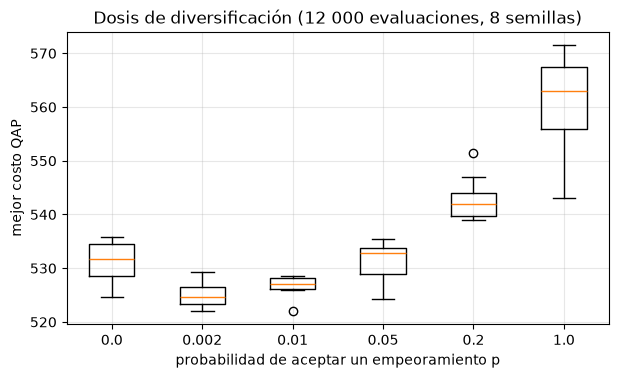

In [10]:
Fq, Dq = crear_qap(18, np.random.default_rng(11))

def buscador_ruidoso(F, D, p_acepta, evals, rng):
    n = len(F); p = rng.permutation(n); c = costo_qap(F, D, p); mejor = c
    for e in range(evals):
        i, j = rng.choice(n, 2, replace=False)
        p[i], p[j] = p[j], p[i]
        c2 = costo_qap(F, D, p)
        if c2 < c or rng.random() < p_acepta:
            c = c2; mejor = min(mejor, c)
        else:
            p[i], p[j] = p[j], p[i]            # deshacer
    assert es_permutacion(p, n)
    return mejor

ps = [0.0, 0.002, 0.01, 0.05, 0.2, 1.0]
res = {}
for pa in ps:
    res[pa] = [buscador_ruidoso(Fq, Dq, pa, 12000, np.random.default_rng(100 + s)) for s in range(8)]
print(f"{'p(aceptar peor)':>16} {'media':>10} {'mejor':>10} {'peor':>10}")
for pa in ps:
    print(f"{pa:>16} {np.mean(res[pa]):>10.2f} {np.min(res[pa]):>10.2f} {np.max(res[pa]):>10.2f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot([res[pa] for pa in ps], tick_labels=[str(pa) for pa in ps])
ax.set_xlabel("probabilidad de aceptar un empeoramiento p"); ax.set_ylabel("mejor costo QAP"); ax.set_title("Dosis de diversificación (12 000 evaluaciones, 8 semillas)")
plt.show()

Mira la tabla: los extremos son los peores. $p=1$ (caminata aleatoria, pura diversificación) queda claramente por detrás, y $p=0$ (pura intensificación) rinde peor que una dosis **pequeña** de ruido (valores como $p=0.002$ o $0.01$ en esta corrida), porque se estanca en el primer óptimo local. El resultado es una curva en U: poca exploración atasca, demasiada impide refinar. No hay un $p$ universal: la dosis óptima **depende del problema y del presupuesto**; por eso en las notebooks de [recocido simulado](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb) y de [ajuste de parámetros](../05-evaluacion-y-ajuste/15-ajuste-de-parametros.ipynb) la exploración se regula de forma explícita y se *calibra* con experimentos.

## 7. Taxonomía de las metaheurísticas

Dos criterios clásicos (Blum & Roli, 2003; Talbi, 2009) permiten ordenar la familia:

1. **Una solución vs. una población.** Los *métodos de trayectoria* mantienen una sola solución actual que sigue una trayectoria en el espacio; los *métodos poblacionales* mantienen un conjunto y lo hacen evolucionar.
2. **Con memoria vs. sin memoria.** Algunos usan solo el estado actual (sin memoria, "markovianos"); otros acumulan información de la historia (listas tabú, feromonas, élites, parámetros adaptativos).

| | **Sin memoria** | **Con memoria** |
|---|---|---|
| **Trayectoria** | Búsqueda local, recocido simulado, ILS (básico), VNS | Búsqueda tabú, GRASP con *path relinking*, ILS con memoria |
| **Población** | Algoritmos genéticos clásicos, evolución diferencial, PSO básico | Colonia de hormigas (feromona), *scatter search*, EDA, GA/PSO con archivos élite |

La frontera es difusa (según la variante, un mismo método cambia de casilla); la taxonomía es una **ayuda para pensar**, no una clasificación rígida.

Otros ejes útiles: inspirada en la naturaleza vs. no; determinista vs. estocástica; función objetivo estática vs. dinámica; una vs. varias estructuras de vecindario. Un patrón de diseño recurrente son las **componentes**: *construcción* (¿cómo genero una solución?), *mejora* (¿cómo la afino?), *perturbación/variación* (¿cómo escapo?), *aceptación* (¿qué reemplazo?) y *memoria*. Aprender metaheurísticas es aprender a **reconocer y combinar esas piezas**; cada notebook de la serie enfatiza una.

Mapa de la serie:
[02 constructivos](../01-metodos-de-trayectoria/02-metodos-constructivos.ipynb) → [03 búsqueda local/ILS](../01-metodos-de-trayectoria/03-busqueda-local-ils.ipynb) → [04 VNS/LNS](../01-metodos-de-trayectoria/04-vns-lns.ipynb) → [05 recocido](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb) → [06 tabú](../02-metodos-con-memoria/06-busqueda-tabu.ipynb) → [07 GRASP/PR](../02-metodos-con-memoria/07-grasp-path-relinking.ipynb) → [08 hormigas](../02-metodos-con-memoria/08-colonia-de-hormigas.ipynb) → [09 genéticos](../03-metodos-poblacionales/09-algoritmos-geneticos.ipynb) → [10 BRKGA/meméticos](../03-metodos-poblacionales/10-brkga-memeticos-scatter-search.ipynb) → [11 PSO/DE](../03-metodos-poblacionales/11-enjambre-pso-evolucion-diferencial.ipynb).

### Un esqueleto común para métodos de trayectoria
Casi todas las metaheurísticas de trayectoria encajan en este molde; lo único que cambia es qué se pone en cada hueco:

```
s ← solución_inicial()                  # construcción (notebook 02)
s* ← s
mientras no se agote el presupuesto:
    s' ← vecino_o_perturbación(s)       # vecindario / perturbación (notebooks 03, 04)
    si aceptar(s, s', historia):        # criterio de aceptación (05: recocido; 06: tabú)
        s ← s'
    si f(s) < f(s*): s* ← s
devolver s*
```

Lo ilustramos con el mismo esqueleto y tres criterios de aceptación sobre un vecindario 2-opt aleatorio en el TSP de $n=60$ (el tiempo no importa aquí: se compara con igual número de evaluaciones, 30 000).

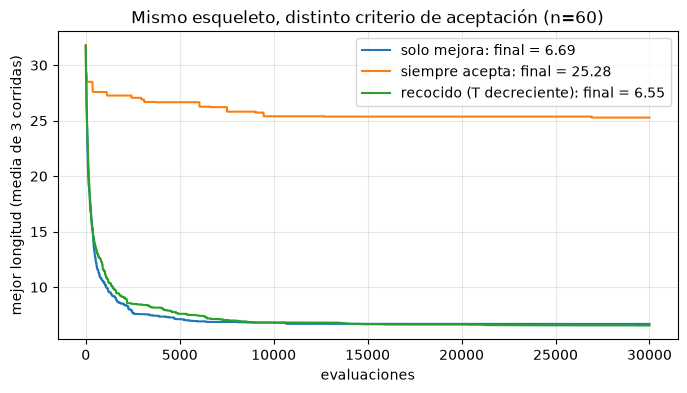

In [11]:
def vecino_2opt_aleatorio(tour, rng):
    # Invierte un tramo aleatorio [i, j] (movimiento 2-opt): cambia solo 2 aristas.
    n = len(tour); i, j = np.sort(rng.choice(n, 2, replace=False))
    nuevo = tour.copy(); nuevo[i:j + 1] = nuevo[i:j + 1][::-1]
    return nuevo

def busqueda_trayectoria(D, aceptar, evals, rng):
    s = rng.permutation(len(D)); fs = longitud_tour(D, s); mejor = fs; traza = np.empty(evals)
    for e in range(evals):
        s2 = vecino_2opt_aleatorio(s, rng); f2 = longitud_tour(D, s2)
        if aceptar(fs, f2, e, evals, rng):
            s, fs = s2, f2
        mejor = min(mejor, fs); traza[e] = mejor
    assert es_permutacion(s, len(D)) and abs(longitud_tour(D, s) - fs) < 1e-9
    return mejor, traza

acep_mejora   = lambda f, f2, e, E, rng: f2 < f                                    # solo mejora (intensificación pura)
acep_siempre  = lambda f, f2, e, E, rng: True                                      # caminata aleatoria (diversificación pura)
acep_recocido = lambda f, f2, e, E, rng: f2 < f or rng.random() < np.exp(-(f2 - f) / (0.05 * (1 - e / E) + 1e-3))  # temperatura decreciente

_, D_t = crear_tsp(60, np.random.default_rng(5))
fig, ax = plt.subplots(figsize=(8, 4))
for nombre, ac in [("solo mejora", acep_mejora), ("siempre acepta", acep_siempre), ("recocido (T decreciente)", acep_recocido)]:
    trazas = np.array([busqueda_trayectoria(D_t, ac, 30000, np.random.default_rng(s))[1] for s in range(3)])
    ax.plot(trazas.mean(axis=0), label=f"{nombre}: final = {trazas[:, -1].mean():.2f}")
ax.set_xlabel("evaluaciones"); ax.set_ylabel("mejor longitud (media de 3 corridas)"); ax.set_title("Mismo esqueleto, distinto criterio de aceptación (n=60)")
ax.legend(); plt.show()

El criterio de aceptación por sí solo ya cambia el comportamiento (compara las longitudes finales impresas en la leyenda). La notebook [05 · Recocido simulado](../01-metodos-de-trayectoria/05-aleatorizados-recocido-simulado.ipynb) justifica y calibra la regla de la tercera curva (aquí la temperatura inicial se fijó a ojo; una calibración mala la deja peor que el ascenso, como ocurre si la subes a $0.5$).

## 8. El teorema *No Free Lunch* (NFL)

**Enunciado informal** (Wolpert & Macready, 1997): promediado sobre **todas** las funciones objetivo posibles $f:X\to Y$ (con $X$, $Y$ finitos), cualquier par de algoritmos que no repiten evaluaciones tiene exactamente la misma distribución de resultados. Formalmente, para toda traza de valores observados $d_m^y$ tras $m$ evaluaciones distintas:

$$
\sum_{f} P\!\left(d_m^y \mid f, m, a_1\right)=\sum_{f} P\!\left(d_m^y \mid f, m, a_2\right).
$$

**Qué significa y qué no significa**
- No significa que todos los algoritmos sean iguales *en problemas reales*. El conjunto de **todas** las funciones incluye ruido blanco sin estructura alguna; los problemas reales tienen estructura (vecindarios que correlacionan, simetrías, etc.).
- Significa que **toda ventaja viene de suponer algo del problema**: un algoritmo supera a otro solo si sus *sesgos inductivos* coinciden con la estructura de la clase de problemas. Por eso la pregunta correcta es "¿qué algoritmo es apropiado para *esta clase* de problemas?" y no "¿cuál es el mejor?".
- Hay refinamientos: la igualdad exacta requiere que el conjunto de funciones sea cerrado bajo permutaciones del dominio (Schumacher, Vose & Whitley, 2001; Igel & Toussaint, 2004).

### Verificación por enumeración exacta
Tomamos $X=\{0,1,2,3\}$, $Y=\{0,1,2\}$ ($3^4=81$ funciones). Comparamos dos algoritmos deterministas sin repetición: **A** recorre $0,1,2,3$ en orden; **B** es *adaptativo*: empieza en $1$ y elige el siguiente punto según el último valor visto. Calculamos exactamente el valor medio de "mejor valor hasta ahora" tras $m$ evaluaciones, sobre las 81 funciones, y luego sobre una clase con estructura (funciones no decrecientes).

In [12]:
X_pts = [0, 1, 2, 3]
funciones = list(itertools.product(range(3), repeat=4))          # f[x] = valor en x

def algoritmo_A(f):
    # Orden fijo 0,1,2,3
    return [f[x] for x in [0, 1, 2, 3]]

def algoritmo_B(f):
    # Adaptativo: parte de x=1; si el último valor es <=1 va al menor punto no visitado, si no, al mayor.
    visitados = [1]; vals = [f[1]]
    while len(visitados) < 4:
        libres = [x for x in X_pts if x not in visitados]
        x = min(libres) if vals[-1] <= 1 else max(libres)
        visitados.append(x); vals.append(f[x])
    return vals

def media_mejor(clase, alg):
    return np.mean([np.minimum.accumulate(alg(f)) for f in clase], axis=0)

todas = funciones
monotonas = [f for f in funciones if all(f[i] <= f[i + 1] for i in range(3))]
print("m =                          ", [1, 2, 3, 4])
for nombre, clase in [("TODAS (81)", todas), (f"no decrecientes ({len(monotonas)})", monotonas)]:
    a, b = media_mejor(clase, algoritmo_A), media_mejor(clase, algoritmo_B)
    print(f"{nombre:>24}  A: {np.round(a, 3)}   B: {np.round(b, 3)}")
assert np.allclose(media_mejor(todas, algoritmo_A), media_mejor(todas, algoritmo_B))

m =                           [1, 2, 3, 4]
              TODAS (81)  A: [1.    0.556 0.333 0.21 ]   B: [1.    0.556 0.333 0.21 ]
    no decrecientes (15)  A: [0.4 0.4 0.4 0.4]   B: [0.8 0.6 0.6 0.4]


Sobre **todas** las funciones, A y B son idénticos (el `assert` lo comprueba). Sobre la clase estructurada, **A gana** (valores menores = mejor) porque su orden de visita coincide con la estructura ("el mínimo está a la izquierda"). Moraleja operativa: *incorpora conocimiento del problema* (vecindarios, constructivos, operadores) y **reporta contra qué clase de instancias** evalúas.

## 9. La búsqueda aleatoria como línea base

Antes de presumir un algoritmo sofisticado, hay que superar a la **búsqueda aleatoria**: muestrear soluciones factibles uniformemente y quedarse con la mejor. Es trivial, sin sesgos y sirve de piso.

**Propiedades útiles para TSP.** Para un tour aleatorio uniforme, cada arista $(\pi(k),\pi(k+1))$ es un par ordenado de ciudades distintas equiprobable, así que

$$
\mathbb{E}[L(\pi)] = n\cdot \bar d, \qquad \bar d=\frac{1}{n(n-1)}\sum_{i\ne j}d_{ij}.
$$

Y la probabilidad de que un único muestreo sea *un* tour óptimo es $\ge \frac{1}{(n-1)!/2}\cdot$(número de óptimos) en el espacio de tours distintos, es decir, ínfima. Con $m$ muestras, el mejor valor mejora solo **lentamente** en $m$ (es un estadístico de orden de una distribución con cola izquierda delgada).

E[L] teórica = n*dbar = 32.243 | media empírica (2e5 tours) = 32.239 | desv.est. = 1.754


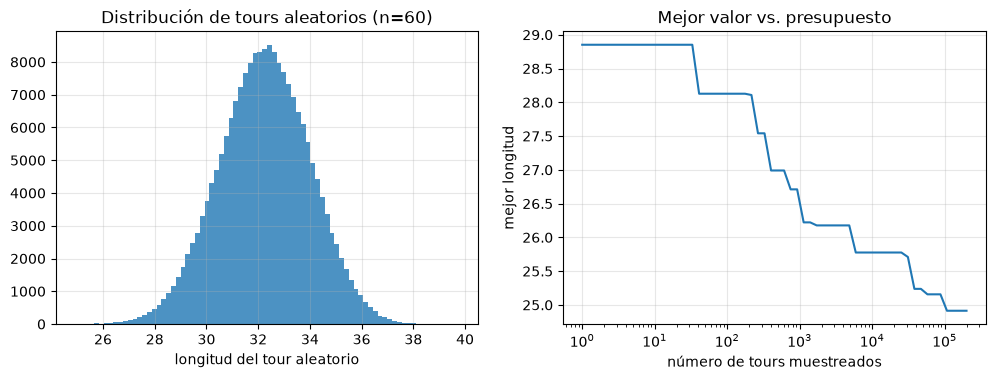

mejor@    10 = 28.852 -> mejor@   100 = 28.127  (ganancia 0.725)
mejor@   100 = 28.127 -> mejor@  1000 = 26.396  (ganancia 1.731)
mejor@  1000 = 26.396 -> mejor@ 10000 = 25.776  (ganancia 0.620)
mejor@ 10000 = 25.776 -> mejor@100000 = 24.914  (ganancia 0.862)


In [13]:
n = 60
pts60, D60 = crear_tsp(n, np.random.default_rng(5))

def muestras_aleatorias(D, m, rng, bloque=20000):
    # Genera m tours aleatorios en bloques y devuelve sus longitudes.
    n = len(D); out = []
    for s in range(0, m, bloque):
        k = min(bloque, m - s)
        P = rng.permuted(np.tile(np.arange(n), (k, 1)), axis=1)
        out.append(D[P, np.roll(P, -1, axis=1)].sum(axis=1))
    return np.concatenate(out)

L = muestras_aleatorias(D60, 200000, np.random.default_rng(0))
dbar = D60.sum() / (n * (n - 1))
print(f"E[L] teórica = n*dbar = {n*dbar:.3f} | media empírica (2e5 tours) = {L.mean():.3f} | desv.est. = {L.std():.3f}")

mejor_acum = np.minimum.accumulate(L)
ms = np.unique(np.logspace(0, np.log10(len(L)), 60).astype(int))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(L, bins=80, color="C0", alpha=0.8); axes[0].set_xlabel("longitud del tour aleatorio"); axes[0].set_title("Distribución de tours aleatorios (n=60)")
axes[1].semilogx(ms, mejor_acum[ms - 1]); axes[1].set_xlabel("número de tours muestreados"); axes[1].set_ylabel("mejor longitud"); axes[1].set_title("Mejor valor vs. presupuesto")
plt.show()
for a, b in [(10, 100), (100, 1000), (1000, 10000), (10000, 100000)]:
    print(f"mejor@{a:>6} = {mejor_acum[a-1]:.3f} -> mejor@{b:>6} = {mejor_acum[b-1]:.3f}  (ganancia {mejor_acum[a-1]-mejor_acum[b-1]:.3f})")

Ahora una **heurística elemental** para comparar: el **vecino más cercano** (NN; construir el tour yendo siempre a la ciudad no visitada más cercana, $O(n^2)$), y un **ascenso con swap** (búsqueda local ingenua con recomputación completa) que sirve de adelanto a las notebooks 02 y 03. Los comparamos en una instancia de $n=14$ donde conocemos el **óptimo exacto** (Held–Karp), y en una de $n=60$ donde usamos el **mejor valor conocido**.

In [14]:
def vecino_mas_cercano(D, inicio=0):
    n = len(D); visitado = np.zeros(n, bool); tour = [inicio]; visitado[inicio] = True
    for _ in range(n - 1):
        d = np.where(visitado, np.inf, D[tour[-1]])
        j = int(d.argmin()); tour.append(j); visitado[j] = True
    return np.array(tour)

def ascenso_swap(D, tour):
    # Mejor-mejora con vecindario swap y recomputación completa (lento pero evidente).
    tour = tour.copy(); n = len(tour); mejor = longitud_tour(D, tour)
    mejorado = True
    while mejorado:
        mejorado = False; bi = bj = None
        for i in range(n - 1):
            for j in range(i + 1, n):
                tour[i], tour[j] = tour[j], tour[i]
                c = longitud_tour(D, tour)
                tour[i], tour[j] = tour[j], tour[i]
                if c < mejor - 1e-12: mejor, bi, bj, mejorado = c, i, j, True
        if mejorado: tour[bi], tour[bj] = tour[bj], tour[bi]
    return tour, mejor

def gap(costo, ref):
    # Gap relativo porcentual respecto a una referencia (óptimo, cota o mejor conocido).
    return 100.0 * (costo - ref) / ref

# --- n = 14: con óptimo exacto ---
pts14, D14 = crear_tsp(14, np.random.default_rng(21))
opt14, tour_opt14 = tsp_held_karp(D14)
rs = np.random.default_rng(1)
alea = muestras_aleatorias(D14, 1000, rs)
nn = [longitud_tour(D14, vecino_mas_cercano(D14, s)) for s in range(14)]
asc = []
for s in range(10):
    t, c = ascenso_swap(D14, rs.permutation(14)); assert es_permutacion(t, 14); asc.append(c)

tabla = {
    "Aleatorio (1 muestra, media)": alea.mean(),
    "Aleatorio (mejor de 1000)": alea.min(),
    "Vecino más cercano (media 14 inicios)": np.mean(nn),
    "Vecino más cercano (mejor inicio)": np.min(nn),
    "Ascenso swap (media 10 inicios)": np.mean(asc),
    "Ascenso swap (mejor)": np.min(asc),
}
print(f"Óptimo exacto (Held-Karp) n=14: {opt14:.4f}")
for k, v in tabla.items():
    print(f"{k:<40} {v:8.4f}   gap = {gap(v, opt14):6.2f} %")

Óptimo exacto (Held-Karp) n=14: 3.1526
Aleatorio (1 muestra, media)               7.4704   gap = 136.95 %
Aleatorio (mejor de 1000)                  4.6537   gap =  47.61 %
Vecino más cercano (media 14 inicios)      3.5335   gap =  12.08 %
Vecino más cercano (mejor inicio)          3.1526   gap =   0.00 %
Ascenso swap (media 10 inicios)            3.2563   gap =   3.29 %
Ascenso swap (mejor)                       3.1526   gap =   0.00 %


Referencia (mejor conocido, n=60): 6.3712   [el ascenso swap tardó 0.1s con recomputación completa]
Aleatorio (mejor de 1e5)      24.5564   gap vs. mejor conocido =  285.43 %
Aleatorio (media)             32.2518   gap vs. mejor conocido =  406.21 %
NN (mejor de 60 inicios)       6.7053   gap vs. mejor conocido =    5.24 %
NN + ascenso swap              6.3712   gap vs. mejor conocido =    0.00 %


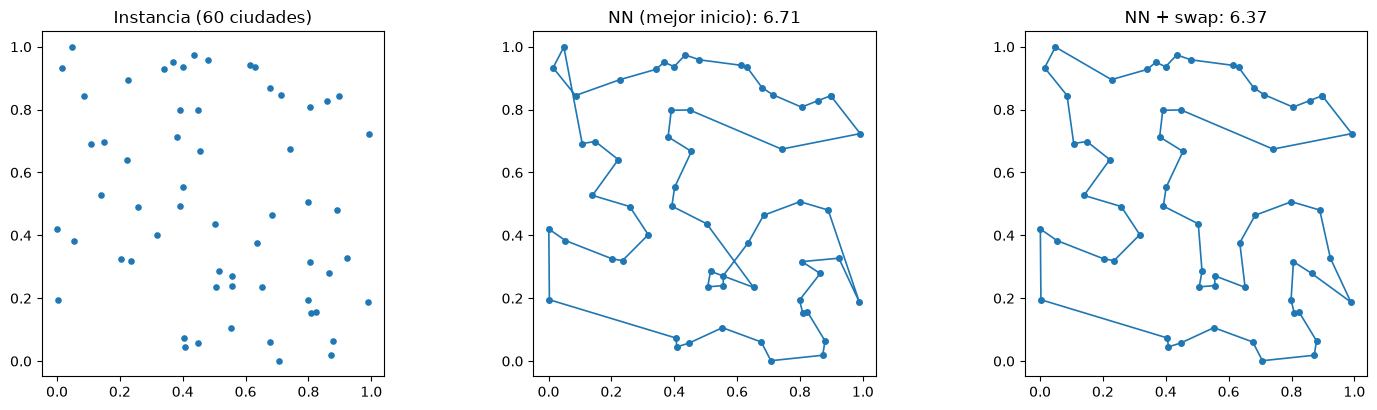

In [15]:
# --- n = 60: referencia = mejor valor conocido (mejor de todo lo ejecutado) ---
rs60 = np.random.default_rng(2)
alea60 = muestras_aleatorias(D60, 100000, rs60)
nn60 = [longitud_tour(D60, vecino_mas_cercano(D60, s)) for s in range(60)]
t_nn = vecino_mas_cercano(D60, int(np.argmin(nn60)))
t0 = time.perf_counter(); t_as, c_as = ascenso_swap(D60, t_nn); t_as_s = time.perf_counter() - t0
assert es_permutacion(t_as, 60) and abs(longitud_tour(D60, t_as) - c_as) < 1e-9
ref = min(alea60.min(), min(nn60), c_as)
print(f"Referencia (mejor conocido, n=60): {ref:.4f}   [el ascenso swap tardó {t_as_s:.1f}s con recomputación completa]")
for k, v in [("Aleatorio (mejor de 1e5)", alea60.min()), ("Aleatorio (media)", alea60.mean()),
             ("NN (mejor de 60 inicios)", min(nn60)), ("NN + ascenso swap", c_as)]:
    print(f"{k:<28} {v:8.4f}   gap vs. mejor conocido = {gap(v, ref):7.2f} %")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].scatter(pts60[:, 0], pts60[:, 1], s=14); axes[0].set_title("Instancia (60 ciudades)"); axes[0].set_aspect("equal"); axes[0].grid(False)
graficar_tour(pts60, t_nn, axes[1], f"NN (mejor inicio): {min(nn60):.2f}")
graficar_tour(pts60, t_as, axes[2], f"NN + swap: {c_as:.2f}")
plt.tight_layout(); plt.show()

Dos lecciones, que puedes contrastar con los gaps impresos: (i) la búsqueda aleatoria, incluso con $10^5$ muestras, queda **muy lejos** de una heurística constructiva trivial como NN, y (ii) una búsqueda local corta sobre NN todavía mejora la solución. Nota que en $n=60$ la referencia es el mejor valor obtenido por nosotros mismos, de modo que un gap de 0 solo significa "el mejor que vimos", no "óptimo". En $n=14$, en cambio, el gap es contra el óptimo exacto. Cualquier metaheurística que presentes debe, como mínimo, **superar a estas líneas base con el mismo presupuesto**.

Sobre el `ascenso_swap`: es deliberadamente ingenuo (cada vecino se evalúa recomputando el tour en $O(n)$, por lo que un barrido cuesta $O(n^3)$). En la notebook 03 lo reemplazamos por evaluación incremental $O(1)$ y vecindarios mejores.

## 10. Cómo medir: gap, cotas y mejor valor conocido

Para un problema de minimización con una referencia $f_{\text{ref}}$:

$$
\text{gap}(\%)=100\cdot\frac{f(x)-f_{\text{ref}}}{f_{\text{ref}}}.
$$

La **referencia** puede ser:

| Referencia | Qué dice el gap | Cuidado |
|---|---|---|
| **Óptimo exacto** | Distancia real al óptimo | Solo en instancias que un exacto resuelve |
| **Cota inferior** (relajación, 1-tree, LP) | *Techo* del gap real: gap real $\le$ gap vs. cota | La cota puede ser floja |
| **Mejor valor conocido** | Comparación relativa al estado del arte | Puede no ser óptimo; si es la mejor *de tus corridas*, sesga a tu favor |
| **Otro algoritmo (línea base)** | Mejora relativa | Cuidado con la equidad del presupuesto |

Buenas prácticas, que se profundizan en [14 · Medición de desempeño](../05-evaluacion-y-ajuste/14-medicion-de-desempeno.ipynb):
1. **Varias corridas** por instancia y varias instancias (estocástico $\Rightarrow$ distribución, no un número).
2. **Mismo presupuesto** (evaluaciones o tiempo) entre métodos.
3. Reportar **media, mejor y dispersión** (y pruebas estadísticas no paramétricas).
4. Separar **calidad vs. tiempo** (curvas de convergencia).
5. Verificar la **factibilidad** de cada solución reportada.

Cota inferior sencilla para TSP: el costo de un **1-tree** (árbol de expansión mínimo más dos aristas) acota por debajo al óptimo; lo implementamos en la notebook [02 · Métodos constructivos](../01-metodos-de-trayectoria/02-metodos-constructivos.ipynb).

## 11. Crítica a la metáfora

Un fenómeno visible en el campo es la proliferación de métodos "inspirados" en hormigas, luciérnagas, lobos grises, ballenas, murciélagos, cucos, etc. Sörensen (2015) argumenta, con ejemplos, que muchos de ellos son **variantes disfrazadas** de ideas conocidas (recocido, búsqueda por poblaciones, recombinación) cuya "novedad" es sobre todo un vocabulario nuevo; que la metáfora **oscurece** en lugar de explicar los componentes algorítmicos; y que las comparaciones a menudo son poco rigurosas (benchmarks pequeños, parámetros sin ajustar para los rivales, sin pruebas estadísticas).

Cómo usar este conocimiento en la práctica:

1. **Describe el algoritmo en términos de sus componentes** (solución, vecindario, aceptación, memoria, variación), no de la metáfora. Si no puedes decir *qué mecanismo* nuevo aporta, probablemente sea una variante de algo existente.
2. **Compara con equidad:** mismo presupuesto, parámetros calibrados para todos, instancias diversas, varias corridas, estadística.
3. **Evalúa contra líneas base fuertes** (búsqueda aleatoria, ILS, recocido bien ajustado), no solo contra versiones débiles.
4. **Conserva la metáfora como intuición pedagógica** (feromona = memoria colectiva; temperatura = tolerancia al empeoramiento), pero la *formulación matemática* debe poder leerse sin ella.

Esto no invalida las metaheurísticas clásicas bien fundamentadas (recocido simulado, búsqueda tabú, algoritmos genéticos, ILS...), sino que pide **rigor**.

## 12. Resumen

- Optimización combinatoria: $(X,\mathcal{F},f)$ con $X$ discreto; el tamaño del espacio explota (factorial/exponencial) y mucho de lo interesante es NP-difícil.
- Los **exactos** (Held–Karp, B&B) dan garantías pero escalan mal; las **metaheurísticas** son marcos generales que cambian garantía por escalabilidad y flexibilidad.
- Un **vecindario** define el paisaje: los óptimos locales y sus cuencas dependen de él. Con enumeración exhaustiva vimos cuántos hay y qué tamaño tienen sus cuencas.
- **Intensificación vs. diversificación** es el eje de diseño universal.
- Taxonomía: trayectoria/población × sin/con memoria.
- **NFL**: sin supuestos sobre el problema no hay algoritmo mejor; toda ventaja viene de sesgos adecuados. Verificado por enumeración.
- La **búsqueda aleatoria** es la línea base mínima; reporta **gap** contra óptimo, cota o mejor conocido, con varias corridas y presupuesto igual.
- Cuidado con la metáfora: describe componentes, no animales.

## Ejercicios propuestos

1. **Tamaño del espacio.** Para QAP con $n=25$, calcula $n!$ y el tiempo de enumeración a $10^9$ evaluaciones/s. ¿Cuánto crece al pasar a $n=26$?
2. **Vecindario y óptimos locales.** Repite la sección 5.2 con el vecindario *swap no adyacente* en lugar de 2-opt. ¿Cambia el número de óptimos locales? ¿Y la fracción de la cuenca del óptimo global?
3. **Otra instancia.** Cambia la semilla de la instancia de $n=9$ y repite el análisis de cuencas. ¿Qué tan estable es la conclusión sobre la cuenca del global?
4. **Mochila con penalización.** Implementa un ascenso por *bit-flip* con una penalización $f(x)=v^\top x-\lambda\max(0,w^\top x-W)$ y estudia el efecto de $\lambda$. Compara con una reparación (quitar ítems de menor razón $v/w$).
5. **NFL.** Con el código de la sección 8, diseña una clase de funciones donde B supere a A, y comprueba que si extiendes la clase cerrándola bajo permutaciones del dominio, la ventaja desaparece.
6. **Línea base aleatoria.** Estima cuántas muestras aleatorias harían falta para igualar al vecino más cercano en la instancia de $n=60$, extrapolando la curva de la sección 9 (regresión sobre $\log m$). Discute la validez de la extrapolación.
7. **Dosis de diversificación.** En el experimento de la sección 6, aumenta el presupuesto a $60\,000$ evaluaciones: ¿se mueve el mejor $p$? Relaciónalo con el equilibrio exploración/explotación según el presupuesto.

## Referencias

- Garey, M. R. & Johnson, D. S. (1979). *Computers and Intractability: A Guide to the Theory of NP-Completeness*. W. H. Freeman.
- Held, M. & Karp, R. M. (1962). A dynamic programming approach to sequencing problems. *Journal of the Society for Industrial and Applied Mathematics*, 10(1).
- Bellman, R. (1962). Dynamic programming treatment of the travelling salesman problem. *Journal of the ACM*, 9(1).
- Koopmans, T. C. & Beckmann, M. (1957). Assignment problems and the location of economic activities. *Econometrica*, 25(1).
- Blum, C. & Roli, A. (2003). Metaheuristics in combinatorial optimization: Overview and conceptual comparison. *ACM Computing Surveys*, 35(3).
- Talbi, E.-G. (2009). *Metaheuristics: From Design to Implementation*. Wiley.
- Gendreau, M. & Potvin, J.-Y. (eds.) (2010). *Handbook of Metaheuristics* (2nd ed.). Springer.
- Wolpert, D. H. & Macready, W. G. (1997). No free lunch theorems for optimization. *IEEE Transactions on Evolutionary Computation*, 1(1).
- Igel, C. & Toussaint, M. (2004). A no-free-lunch theorem for non-uniform distributions of target functions. *Journal of Mathematical Modelling and Algorithms*, 3.
- Schumacher, C., Vose, M. D. & Whitley, L. D. (2001). The no free lunch and problem description length. *Proceedings of GECCO 2001*.
- Stadler, P. F. (2002). Fitness landscapes. En *Biological Evolution and Statistical Physics*, Springer.
- Wright, S. (1932). The roles of mutation, inbreeding, crossbreeding and selection in evolution. *Proceedings of the Sixth International Congress of Genetics*.
- Sörensen, K. (2015). Metaheuristics—the metaphor exposed. *International Transactions in Operational Research*, 22(1).